# 06 Hybride model: trainen, vergelijken en evalueren

**Workshops:** LU2 `04_PT and model evaluation` (train/test split, metrics) en vorig jaar `04 Decision Trees`,
`05 Random forest` en `06 Neural Network`.

We maken een **hybride model**: voor elk paar (student, materiaal) berekenen we kenmerken uit het profiel, de inhoud en
het gedrag van andere studenten. Een classificatiemodel leert welke combinatie leidt tot een positieve interactie
(de interactietypes die de data zelf als positief beoordeelt: gelezen, geliket en opgeslagen). De voorspelde kans is de score waarop we de catalogus sorteren.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from reading_coach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from reading_coach.data_cleaning import load_processed
from reading_coach.features import FEATURE_COLUMNS, FEATURE_LABELS
from reading_coach.hybrid import HybridRecommender
from reading_coach.evaluation import temporal_split

materials, students, interactions = load_processed()
train, test = temporal_split(interactions)
print(f"train {len(train)} interacties, test {len(test)} interacties")

train 1500 interacties, test 486 interacties


## 1. Kenmerken per (student, materiaal)

Om **data leakage** te voorkomen berekenen we de collaborative score en de populariteit *out of fold*: voor een groep studenten worden die alleen berekend met de interacties van de andere studenten.

In [3]:
recommender = HybridRecommender()
recommender.fit_components(materials, students, train)
train_frame = recommender.training_frame(students, train)

students_by_id = students.set_index("student_id", drop=False)
test_rows = []
for student_id, own_test in test.groupby("student_id"):
    profile = recommender.profile_of(students_by_id.loc[student_id])
    own_train = train[train["student_id"] == student_id]
    history = dict(zip(own_train["catalog_code"], own_train["preference_score"]))
    features = recommender.pair_features(profile, history, codes=own_test["catalog_code"].tolist())
    features["positive"] = own_test["positive"].to_numpy()
    features["student_id"] = student_id
    test_rows.append(features)
test_frame = pd.concat(test_rows)

X_train, y_train = train_frame[FEATURE_COLUMNS], train_frame["positive"]
X_test, y_test = test_frame[FEATURE_COLUMNS], test_frame["positive"]
print(X_train.shape, X_test.shape, f"aandeel positief: {y_train.mean():.2f}")
X_train.describe().T.round(2)

(1500, 14) (486, 14) aandeel positief: 0.30


,count,mean,std,min,25%,50%,75%,max
level_diff,1500.0,-0.06,0.75,-1.50,-0.50,0.00,0.00,1.50
level_distance,1500.0,0.51,0.55,0.00,0.00,0.50,1.00,1.50
type_match,1500.0,0.50,0.43,0.00,0.00,0.50,1.00,1.00
genre_match,1500.0,0.46,0.41,0.00,0.00,0.50,1.00,1.00
interest_sim,1500.0,0.02,0.04,0.00,0.00,0.00,0.03,0.38
interest_hits,1500.0,0.15,0.37,0.00,0.00,0.00,0.00,2.00
history_sim,1500.0,0.01,0.02,0.00,0.00,0.00,0.01,0.20
time_ratio_log,1500.0,1.87,1.12,0.04,0.89,1.96,2.75,4.16
fits_time,1500.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
language_match,1500.0,0.97,0.17,0.00,1.00,1.00,1.00,1.00


## 2. Modellen vergelijken
We vergelijken een simpel model (logistische regressie), een beslisboom, een random forest, gradient boosting en een neuraal netwerk (MLP). Voor modellen die gevoelig zijn voor schaal zetten we een `StandardScaler` in een pipeline.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

candidates = {
    "Logistische regressie": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Beslisboom": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=config.RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=config.RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, class_weight="balanced", random_state=config.RANDOM_STATE),
    "Neuraal netwerk (MLP)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=2000, early_stopping=True, random_state=config.RANDOM_STATE)),
}

rows = []
for name, estimator in candidates.items():
    cv_auc = cross_val_score(estimator, X_train, y_train, groups=train_frame["student_id"], cv=GroupKFold(5), scoring="roc_auc")
    estimator.fit(X_train, y_train)
    probability = estimator.predict_proba(X_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    rows.append({
        "model": name,
        "cv_auc (train)": cv_auc.mean(),
        "auc (test)": roc_auc_score(y_test, probability),
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction),
        "recall": recall_score(y_test, prediction),
        "f1": f1_score(y_test, prediction),
    })
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,cv_auc (train),auc (test),accuracy,precision,recall,f1
model,,,,,,
Logistische regressie,0.839,0.803,0.718,0.512,0.775,0.616
Beslisboom,0.807,0.788,0.698,0.488,0.739,0.588
Random forest,0.852,0.825,0.753,0.559,0.739,0.636
Gradient boosting,0.845,0.814,0.751,0.558,0.711,0.625
Neuraal netwerk (MLP),0.791,0.782,0.733,0.540,0.570,0.555


**Waarom AUC?** We gebruiken de kans om te sorteren, niet om ja of nee te zeggen. AUC meet precies dat: hoe vaak staat
een materiaal dat de student goed vond hoger dan een materiaal dat hij afwees. 0.5 is gokken, 1.0 is perfect.

**Keuze:** het random forest scoort (bijna) het best, is stabiel en geeft *feature importances* die we aan docenten
kunnen laten zien. Daarom is dat het model in `HybridRecommender`.

## 3. De beslisboom bekijken (uitlegbaarheid)

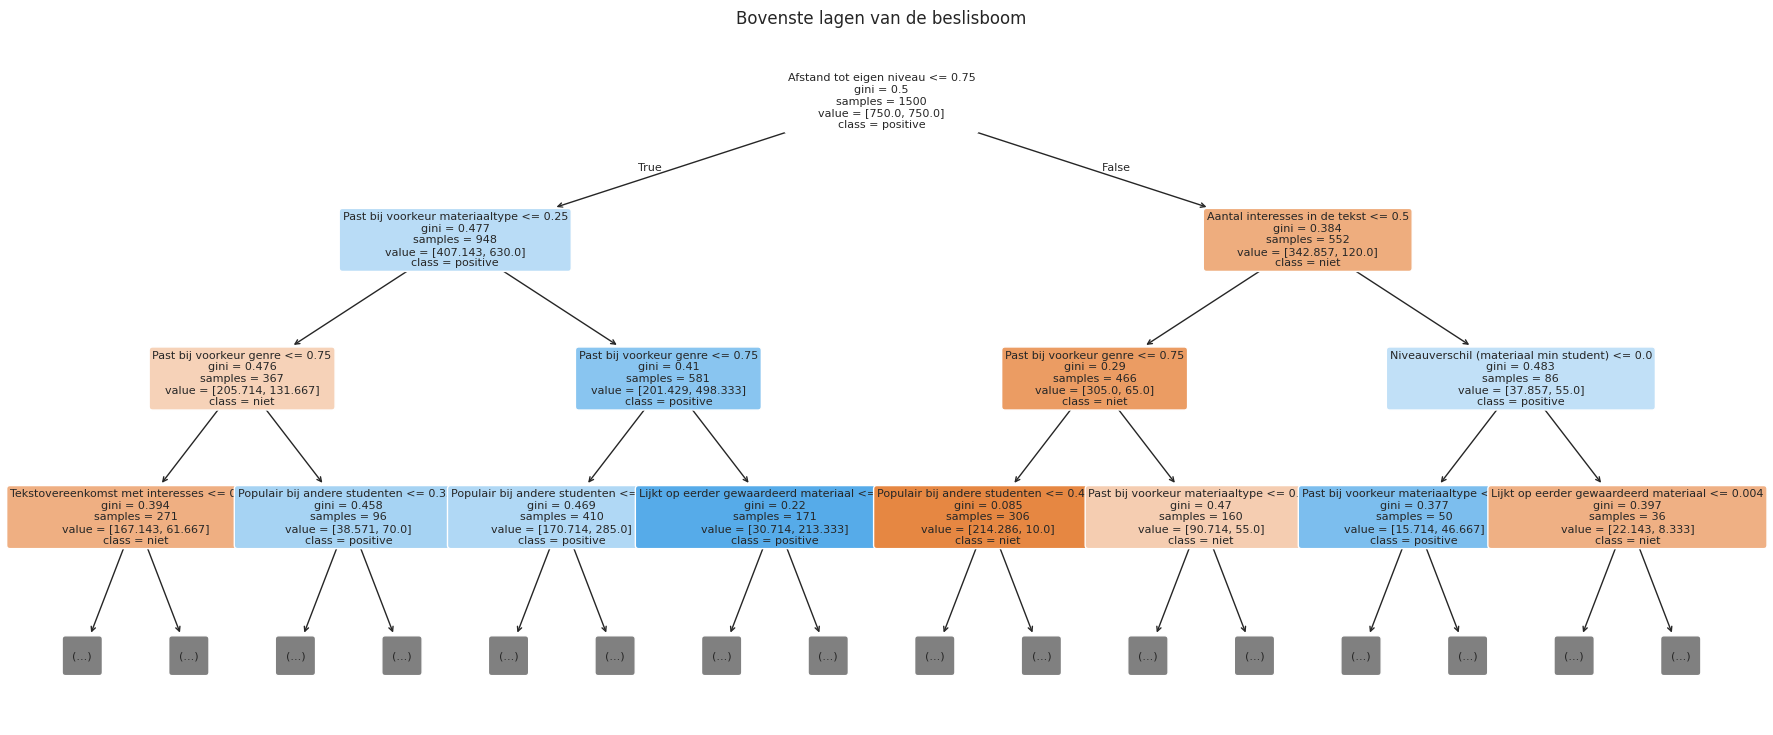

In [5]:
from sklearn.tree import plot_tree

tree = candidates["Beslisboom"]
plt.figure(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=[FEATURE_LABELS[c] for c in FEATURE_COLUMNS], class_names=["niet", "positive"],
          filled=True, rounded=True, fontsize=8)
plt.title("Bovenste lagen van de beslisboom")
plt.savefig(config.FIGURES_DIR / "06_decision_tree.png", dpi=110)
plt.show()

## 4. Wat weegt mee? Feature importance en permutation importance

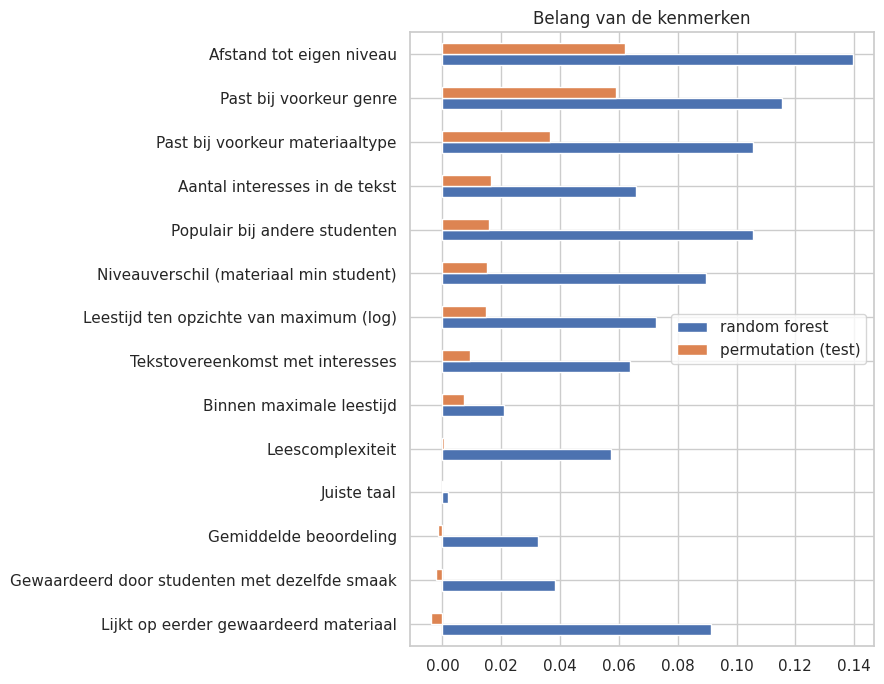

In [6]:
from sklearn.inspection import permutation_importance

forest = candidates["Random forest"]
importance = pd.DataFrame({
    "random forest": pd.Series(forest.feature_importances_, index=FEATURE_COLUMNS),
    "permutation (test)": pd.Series(
        permutation_importance(forest, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=config.RANDOM_STATE).importances_mean,
        index=FEATURE_COLUMNS),
}).rename(index=FEATURE_LABELS).sort_values("permutation (test)")
importance.plot.barh(figsize=(9, 7), title="Belang van de kenmerken")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "06_feature_importance.png", dpi=120)
plt.show()

## 5. Hyperparameters afstemmen
We zoeken de beste instellingen met GridSearchCV, met groepen per student zodat dezelfde student niet in train en validatie zit.

In [7]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=config.RANDOM_STATE, n_jobs=-1),
    param_grid={"max_depth": [4, 8, 12, None], "min_samples_leaf": [1, 5, 15]},
    scoring="roc_auc",
    cv=GroupKFold(5),
)
grid.fit(X_train, y_train, groups=train_frame["student_id"])
print("Beste instellingen:", grid.best_params_, "AUC", round(grid.best_score_, 3))
pd.DataFrame(grid.cv_results_).pivot_table(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)

Beste instellingen: {'max_depth': None, 'min_samples_leaf': 5} AUC 0.854


param_min_samples_leaf,1,5,15
param_max_depth,,,
4,0.850,0.850,0.849
8,0.851,0.852,0.852
12,0.849,0.854,0.853


## 6. Kalibratie: klopt de kans?
Als het model 0.7 zegt, wordt het materiaal dan ook ongeveer 70% van de keren positief ontvangen?

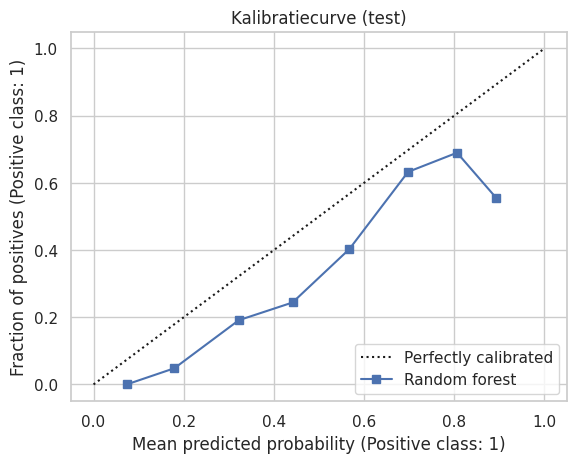

In [8]:
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_estimator(forest, X_test, y_test, n_bins=8, name="Random forest")
plt.title("Kalibratiecurve (test)")
plt.show()

## 7. Als recommender: top 5 uit de hele catalogus
Nu het echte doel: als we de hele catalogus sorteren, staan de materialen die de student later goed vond dan in de top 5? We vergelijken met eenvoudige alternatieven, waaronder de regels uit de eerste versie van de Fastify app.

In [9]:
from reading_coach.evaluation import catalog_coverage, evaluate_rankings, make_scorers

model = HybridRecommender().fit(materials, students, train)
ranking = evaluate_rankings(make_scorers(model, train, students), model, students, train, test, k=5)
ranking

,precision@5,recall@5,ndcg@5,hitrate@5,auc_test_interactions,auc_per_student
method,,,,,,
Random,0.010,0.021,0.017,0.037,0.499,0.484
Popularity,0.047,0.132,0.121,0.235,0.637,0.649
Rules (first version of the app),0.035,0.116,0.069,0.173,0.643,0.608
Content based (TF-IDF),0.015,0.034,0.028,0.074,0.606,0.608
Item KNN,0.007,0.014,0.009,0.037,0.535,0.536
Matrix factorisation (SVD),0.032,0.110,0.082,0.160,0.612,0.584
Hybrid model (Random Forest),0.069,0.235,0.157,0.321,0.825,0.773


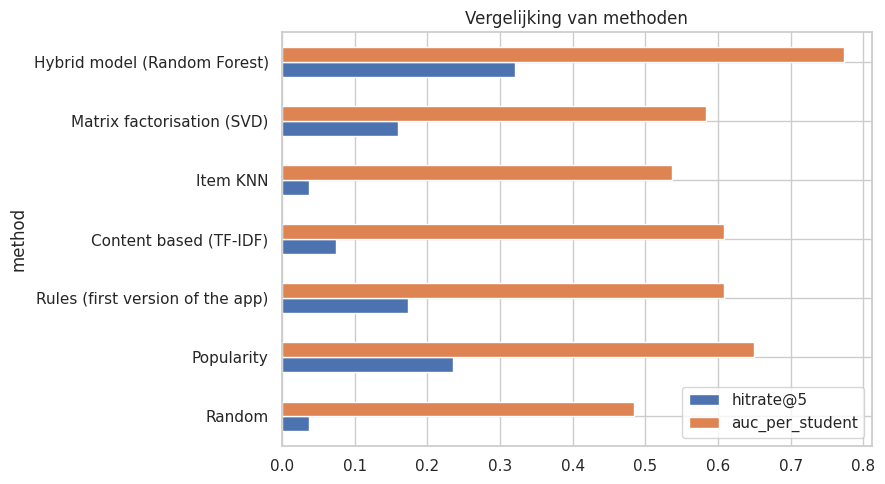

Catalogusdekking: 39% van de catalogus komt in minstens een advies voor


In [10]:
ranking[["hitrate@5", "auc_per_student"]].plot.barh(figsize=(9, 5), title="Vergelijking van methoden")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "06_method_comparison.png", dpi=120)
plt.show()
print(f"Catalogusdekking: {catalog_coverage(model, students, train):.0%} van de catalogus komt in minstens een advies voor")

## 8. Eerlijkheid: werkt het even goed voor elke groep?
We controleren of het model voor elk leesniveau en elke leeftijdsgroep ongeveer even goed werkt. Een groot verschil zou betekenen dat een groep slechter advies krijgt.

In [11]:
groups = test_frame.merge(students[["student_id", "reading_level", "age_group", "cefr_level"]], on="student_id")
groups["probability"] = forest.predict_proba(groups[FEATURE_COLUMNS])[:, 1]
fairness = []
for column in ["reading_level", "age_group", "cefr_level"]:
    for value, part in groups.groupby(column):
        if part["positive"].nunique() == 2:
            fairness.append({"group": column, "value": value, "n": len(part), "auc": roc_auc_score(part["positive"], part["probability"])})
pd.DataFrame(fairness).round(3)

,group,value,n,auc
0,reading_level,2F,274,0.820
1,reading_level,3F,135,0.820
2,reading_level,3F+,77,0.828
3,age_group,16-18,183,0.812
4,age_group,19-21,196,0.823
5,age_group,22+,107,0.848
6,cefr_level,A2,59,0.845
7,cefr_level,B1,150,0.803
8,cefr_level,B2,171,0.865
9,cefr_level,C1,106,0.796


## Conclusie

* Het hybride model rangschikt de test interacties duidelijk beter (AUC 0.82) dan willekeurig, populariteit, alleen
  tekst, alleen collaborative filtering en de regels uit de eerste versie van de app (allemaal rond of onder 0.64).
  Juist het combineren van signalen levert hier de winst op.
* Ook in de top 5 uit de hele catalogus wint het hybride model: een hitrate@5 van 0.32 tegenover 0.24 voor populariteit
  en 0.17 voor de regels. De synoniemen uit de wordnet hielpen hier: zonder was de hitrate@5 0.28, met een
  AUC die iets hoger lag (0.83). Voor de student telt de top 5, dus ik houd de synoniemen. Populariteit blijft een sterke baseline; het hybride model is vooral persoonlijker, het weet wat
  te moeilijk of te lang is.
* De belangrijkste signalen zijn het **niveau**, het **genre**, het **materiaaltype**, de **populariteit**, de
  **tekstovereenkomst met interesses** en de **leestijd**.
* De top 5 precisie is laag in absolute zin. Per student zijn er maar een paar positieve test interacties, terwijl er 275
  materialen zijn: een student kan goede materialen ook gewoon nooit gezien hebben. De AUC per student (0.77) vind ik
  daarom de eerlijkere maat.
* De AUC is voor alle leesniveaus en leeftijden vergelijkbaar. Bij taalniveau B1 en C1 ligt hij iets lager (rond 0.80):
  dat houd ik in de gaten zodra er echte data is.
* De dataset is gesimuleerd. Voordat het model breed ingezet wordt, wil ik het valideren met echte studenten, bijvoorbeeld
  met een A/B test tegen de regels. In de app houd ik daarvoor al bij of een boek via het advies of via de catalogus op de
  leeslijst kwam.
